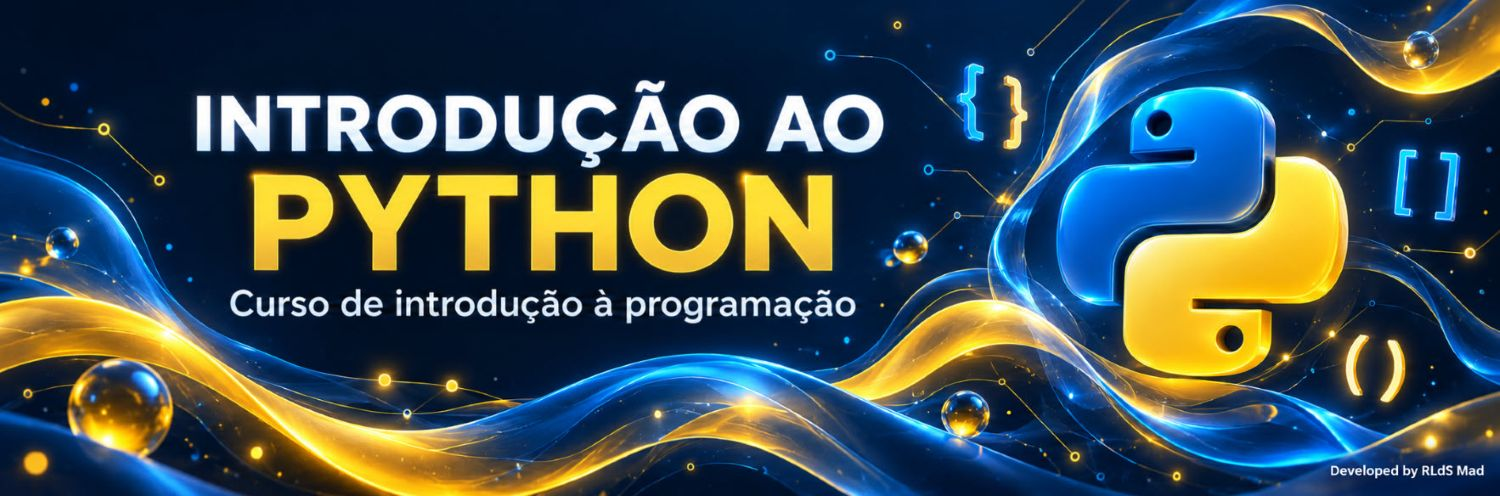

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_10_Dijkstra_Caminhos.ipynb)

# Nível IA · Módulo 10 – Pesquisa em grafos: o algoritmo de Dijkstra
## Caminhos mais curtos, estados aumentados, A*, Bellman-Ford e todos os pares

Qual é a rota mais barata do Porto a Faro? Quanto tempo demora um sinal a chegar a todos os servidores de uma rede? Qual é a forma mais rápida de sair de um labirinto com lama, ou de atravessar uma montanha com o menor esforço? Todas estas perguntas são o mesmo problema: o **caminho mais curto num grafo**. O algoritmo de Dijkstra, publicado em 1959, continua a ser a forma clássica de o resolver.

Os módulos N3_08 e N3_09 usaram **pesquisa local**: partem de uma solução completa e vão-na melhorando, sem garantia de ótimo. Este módulo trata da outra grande família da pesquisa em IA, a **pesquisa sistemática**: constrói a solução passo a passo, explora as alternativas por uma ordem cuidadosa e **garante o ótimo**.

> **Objetivos:** representar grafos em Python; executar o algoritmo de Dijkstra à mão e implementá-lo com uma fila de prioridade (`heapq`); reconstruir caminhos e lidar com empates; perceber porque o Dijkstra está correto e porque falha com pesos negativos; aplicar o Dijkstra a grelhas e a custos *minimax*; modelar problemas com regras extra **aumentando o estado** (escalas, cupões, bateria, chaves); contar expansões e gerações; usar o A* com uma heurística admissível, a pesquisa bidirecional e o IDA* (A* com pouca memória); usar o Bellman-Ford com pesos negativos; calcular distâncias entre todos os pares com Floyd-Warshall e Johnson; escolher o algoritmo certo para cada problema; conhecer os resultados recentes sobre a otimalidade do Dijkstra.

**Pré-requisitos:** dicionários e conjuntos (capítulos 14 e 15), funções (capítulo 18) e visualização (capítulo 24). A ligação ao N3_08 (custo *minimax* e poda) é útil, mas não obrigatória.

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas e vocabulário |
| 1. Grafos em Python | listas de adjacência com dicionários |
| 2. O Dijkstra passo a passo | a ideia e a execução à mão |
| 3. Implementação com fila de prioridade | `heapq`, caminhos, empates, correção e pesos negativos |
| 4. Dijkstra em grelhas | labirinto com lama e terreno montanhoso (*minimax*) |
| 5. Aumentar o estado | escalas, cupões, bateria e chaves |
| 6. A*: pesquisar com uma bússola | heurísticas, pesquisa bidirecional e IDA* |
| 7. Bellman-Ford: quando há pesos negativos | arbitragem de moedas |
| 8. Todos os pares | Floyd-Warshall e Johnson |
| 9. Para saber mais: o Dijkstra é ótimo? | a barreira da ordenação e o resultado de 2025 |
| 10. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 Bibliotecas

Os algoritmos são escritos de raiz com a biblioteca padrão (`heapq` dá-nos a fila de prioridade). A biblioteca `networkx`, que já vem no Colab, serve para desenhar grafos e para **confirmar** os nossos resultados com uma implementação independente.

In [1]:
# Executar esta célula

import heapq
import itertools
import math
import random
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

plt.rcParams.update({"figure.dpi": 100})
print(f"networkx {nx.__version__} | NumPy {np.__version__}")

networkx 3.7 | NumPy 2.5.4


### 0.2 Vocabulário

| Termo | Significado |
| --- | --- |
| **Grafo** | um conjunto de **vértices** (ou nós) ligados por **arestas** |
| **Peso** (ou custo) | o número associado a uma aresta: uma distância, um preço, um tempo |
| **Grafo dirigido** | as arestas têm sentido: ir de A para B não implica poder ir de B para A |
| **Caminho** | uma sequência de vértices ligados por arestas; o seu custo é a soma dos pesos |
| **Fila de prioridade** | uma estrutura que devolve sempre o elemento com menor valor |
| **Relaxar uma aresta** | verificar se passar por ela dá um caminho mais curto até ao destino da aresta e, se sim, atualizar |
| **Expansão** | retirar um estado da fila e gerar os seus sucessores |
| **Geração** | criar um sucessor (um estado vizinho) durante uma expansão |
| **Heurística** | uma estimativa do custo que falta até ao objetivo |

## 1. Grafos em Python

A forma mais prática de guardar um grafo em Python é uma **lista de adjacência** com dicionários: para cada vértice, um dicionário com os vizinhos e os pesos das arestas. É o grafo do primeiro exemplo, dirigido, com 5 vértices:

In [2]:
# Executar esta célula

grafo1 = {
    "A": {"B": 4, "C": 2},
    "B": {"C": 5, "D": 10},
    "C": {"E": 3},
    "D": {},
    "E": {"D": 4},
}
print("Vizinhos de B:", grafo1["B"])
print("Peso da aresta A -> C:", grafo1["A"]["C"])
print("Número de arestas:", sum(len(v) for v in grafo1.values()))

Vizinhos de B: {'C': 5, 'D': 10}
Peso da aresta A -> C: 2
Número de arestas: 6


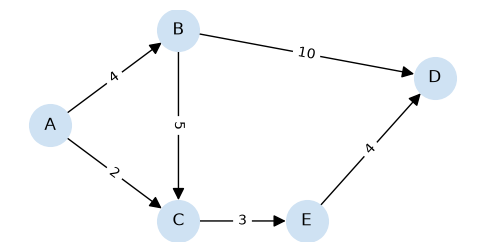

In [3]:
# Executar esta célula

G1 = nx.DiGraph()
for u, vizinhos in grafo1.items():
    for v, peso in vizinhos.items():
        G1.add_edge(u, v, weight=peso)
posicoes = {"A": (0, 1), "B": (1, 2), "C": (1, 0), "D": (3, 1.5), "E": (2, 0)}
fig, ax = plt.subplots(figsize=(6, 3))
nx.draw_networkx(G1, posicoes, ax=ax, node_color="#cfe2f3", node_size=900, arrowsize=18)
nx.draw_networkx_edge_labels(G1, posicoes, edge_labels=nx.get_edge_attributes(G1, "weight"), ax=ax)
ax.set_axis_off()
plt.show()

## 2. O Dijkstra passo a passo

### 2.1 A ideia

O Dijkstra calcula a distância de uma **origem** a **todos** os vértices. Mantém uma distância provisória para cada vértice (no início, 0 na origem e infinito nos restantes) e repete:

```text
enquanto houver vértices por visitar:
    u ← o vértice por visitar com menor distância provisória
    marcar u como visitado: a sua distância passa a ser definitiva
    para cada vizinho v de u:
        se dist[u] + peso(u, v) < dist[v]:      # relaxar a aresta
            dist[v] ← dist[u] + peso(u, v)
            anterior[v] ← u
```

É um algoritmo **guloso**: em cada passo, fixa o vértice mais próximo ainda não visitado. A secção 3.4 explica porque é que essa escolha nunca se engana quando os pesos não são negativos.

### 2.2 Exercício 1: execução passo a passo

**Pergunta:** partindo de A, qual é a menor distância até D, e qual é o caminho?

A função seguinte executa o Dijkstra exatamente como no pseudocódigo (sem fila de prioridade, procurando o mínimo à mão) e regista uma linha da tabela por passo.

In [4]:
# Executar esta célula

def dijkstra_passo_a_passo(grafo, origem):
    dist = {v: math.inf for v in grafo}
    anterior = {v: None for v in grafo}
    dist[origem] = 0
    visitados, linhas = set(), []
    while len(visitados) < len(grafo):
        por_visitar = [v for v in grafo if v not in visitados and dist[v] < math.inf]
        if not por_visitar:
            break
        u = min(por_visitar, key=lambda v: dist[v])
        visitados.add(u)
        atualizados = []
        for v, peso in grafo[u].items():
            if v not in visitados and dist[u] + peso < dist[v]:
                dist[v] = dist[u] + peso
                anterior[v] = u
                atualizados.append(f"{v}={dist[v]}")
        linhas.append({"visita": f"{u} ({dist[u]})", "atualiza": ", ".join(atualizados) or "—",
                       **{v: ("✓ " if v in visitados else "") + ("∞" if dist[v] == math.inf else str(dist[v])) for v in grafo}})
    return dist, anterior, pd.DataFrame(linhas, index=pd.RangeIndex(1, len(linhas) + 1, name="passo"))


def caminho(anterior, destino):
    resultado = []
    while destino is not None:
        resultado.append(destino)
        destino = anterior[destino]
    return resultado[::-1]


dist1, anterior1, tabela = dijkstra_passo_a_passo(grafo1, "A")
tabela

,visita,atualiza,A,B,C,D,E
passo,,,,,,,
1,A (0),"B=4, C=2",✓ 0,4,2,∞,∞
2,C (2),E=5,✓ 0,4,✓ 2,∞,5
3,B (4),D=14,✓ 0,✓ 4,✓ 2,14,5
4,E (5),D=9,✓ 0,✓ 4,✓ 2,9,✓ 5
5,D (9),—,✓ 0,✓ 4,✓ 2,✓ 9,✓ 5


In [5]:
# Executar esta célula

print("Distância de A a D:", dist1["D"])
print("Caminho:", " -> ".join(caminho(anterior1, "D")))

Distância de A a D: 9
Caminho: A -> C -> E -> D


A tabela mostra o essencial do algoritmo (✓ marca os vertices já visitados, com distância definitiva):

- no passo 3, B oferece um caminho para D de custo 14, que fica como provisório;
- no passo 4, ao visitar E (distância 5), descobre-se um caminho melhor para D: 5 + 4 = 9 < 14, e D é atualizado;
- D só fica definitivo no passo 5, quando é o mais próximo dos que faltam.

**Resposta:** a menor distância é **9**, pelo caminho **A → C → E → D**. Repara que o caminho com menos arestas (A → B → D) é mais caro: o Dijkstra minimiza o **custo**, não o número de passos.

## 3. Implementação com fila de prioridade

### 3.1 O `heapq`

Procurar o mínimo à mão em cada passo custa $O(V)$, e o algoritmo fica $O(V^2)$. Com uma **fila de prioridade**, obter o mínimo custa $O(\log V)$. O módulo `heapq` implementa uma fila de prioridade sobre uma lista de Python: `heappush` insere e `heappop` retira o menor elemento. Guardamos tuplos `(distância, vértice)`, que se comparam pela distância.

O `heapq` não permite diminuir a prioridade de um elemento já na fila. A solução habitual é **inserir de novo** com a distância nova e, ao retirar, **ignorar** os elementos de vértices já visitados (que ficaram desatualizados). A fila pode ter entradas repetidas, mas o resultado está certo, e o tempo total é $O((V + E) \log V)$.

A função conta também as **expansões** (vértices retirados da fila e processados) e as **gerações** (vizinhos considerados), as medidas de esforço habituais nos algoritmos de pesquisa.

In [6]:
# Executar esta célula

def dijkstra(grafo, origem):
    dist = {v: math.inf for v in grafo}
    anterior = {v: None for v in grafo}
    dist[origem] = 0
    fila = [(0, origem)]
    visitados = set()
    estatisticas = {"expansões": 0, "gerações": 0}
    while fila:
        d, u = heapq.heappop(fila)
        if u in visitados:  # entrada desatualizada: ignorar
            continue
        visitados.add(u)
        estatisticas["expansões"] += 1
        for v, peso in grafo[u].items():
            estatisticas["gerações"] += 1
            if v not in visitados and d + peso < dist[v]:
                dist[v] = d + peso
                anterior[v] = u
                heapq.heappush(fila, (dist[v], v))
    return dist, anterior, estatisticas


dist, anterior, est = dijkstra(grafo1, "A")
print(dist, "|", " -> ".join(caminho(anterior, "D")), "|", est)
print("Confirmação com networkx:", nx.single_source_dijkstra_path_length(G1, "A"))

{'A': 0, 'B': 4, 'C': 2, 'D': 9, 'E': 5} | A -> C -> E -> D | {'expansões': 5, 'gerações': 6}
Confirmação com networkx: {'A': 0, 'C': 2, 'B': 4, 'E': 5, 'D': 9}


**Vértices inalcançáveis.** Se o grafo tiver vértices isolados, ou partes a que não se chega a partir da origem, a distância desses vértices fica em `math.inf`: o Dijkstra nunca os retira da fila, porque nunca lá entram. Não é um erro, é a resposta: «não há caminho». Para o testar, usa-se `dist[v] == math.inf` (ou `math.isinf(dist[v])`), e o caminho de um vértice inalcançável não deve ser reconstruído, porque não tem antecessores. No grafo abaixo, F e G formam uma componente separada, e D só tem arestas a sair:

In [7]:
# Executar esta célula

grafo_desconexo = {"A": {"B": 1}, "B": {"C": 2}, "C": {}, "D": {"A": 1}, "F": {"G": 1}, "G": {}}
dist, anterior, _ = dijkstra(grafo_desconexo, "A")
inalcancaveis = [v for v, d in dist.items() if d == math.inf]
print("Distâncias:", dist)
print("Inalcançáveis a partir de A:", inalcancaveis)
for destino in ("C", "F"):
    if math.isinf(dist[destino]):
        print(f"A -> {destino}: não há caminho")
    else:
        print(f"A -> {destino}: {' -> '.join(caminho(anterior, destino))} (custo {dist[destino]})")

Distâncias: {'A': 0, 'B': 1, 'C': 3, 'D': inf, 'F': inf, 'G': inf}
Inalcançáveis a partir de A: ['D', 'F', 'G']
A -> C: A -> B -> C (custo 3)
A -> F: não há caminho


### 3.2 Exercício 2: a rota mais barata do Porto a Faro

Uma transportadora quer levar uma encomenda do Porto a Faro gastando o mínimo possível em combustível e portagens. Os custos (em euros, valores ilustrativos) valem nos dois sentidos, por isso cada ligação entra no grafo como **duas** arestas dirigidas.

In [8]:
# Executar esta célula

ligacoes = [("Porto", "Coimbra", 15), ("Porto", "Viseu", 20), ("Coimbra", "Lisboa", 25),
            ("Coimbra", "Castelo Branco", 18), ("Viseu", "Castelo Branco", 12), ("Castelo Branco", "Évora", 22),
            ("Lisboa", "Évora", 14), ("Lisboa", "Faro", 35), ("Évora", "Faro", 20)]

estradas = {}
for a, b, custo in ligacoes:
    estradas.setdefault(a, {})[b] = custo
    estradas.setdefault(b, {})[a] = custo  # bidirecional

dist, anterior, est = dijkstra(estradas, "Porto")
print(f"Custo mínimo Porto -> Faro: {dist['Faro']} €")
print("Rota:", " -> ".join(caminho(anterior, "Faro")))
pd.Series(dist, name="custo desde o Porto (€)").sort_values().to_frame().T

Custo mínimo Porto -> Faro: 74 €
Rota: Porto -> Viseu -> Castelo Branco -> Évora -> Faro


,Porto,Coimbra,Viseu,Castelo Branco,Lisboa,Évora,Faro
custo desde o Porto (€),0,15,20,32,40,54,74


O Dijkstra encontra uma rota de 74 €. Mas há uma subtileza: Évora é alcançada com 54 € por **dois** caminhos (por Castelo Branco e por Lisboa). Com um empate, o algoritmo guarda apenas o primeiro antecessor que encontrou, e devolve **um** caminho ótimo, não todos. Para obter todos, guarda-se uma **lista** de antecessores e acrescenta-se a ela em caso de empate:

In [9]:
# Executar esta célula

def dijkstra_todos_os_antecessores(grafo, origem):
    dist = {v: math.inf for v in grafo}
    antecessores = {v: [] for v in grafo}
    dist[origem] = 0
    fila, visitados = [(0, origem)], set()
    while fila:
        d, u = heapq.heappop(fila)
        if u in visitados:
            continue
        visitados.add(u)
        for v, peso in grafo[u].items():
            if d + peso < dist[v]:
                dist[v], antecessores[v] = d + peso, [u]
                heapq.heappush(fila, (dist[v], v))
            elif d + peso == dist[v] and v not in visitados:
                antecessores[v].append(u)  # empate: outro caminho ótimo
    return dist, antecessores


def todos_os_caminhos(antecessores, destino):
    if not antecessores[destino]:
        return [[destino]]
    return [c + [destino] for a in antecessores[destino] for c in todos_os_caminhos(antecessores, a)]


dist, antecessores = dijkstra_todos_os_antecessores(estradas, "Porto")
for c in todos_os_caminhos(antecessores, "Faro"):
    print(" -> ".join(c), "=", sum(estradas[a][b] for a, b in zip(c, c[1:])), "€")

G_estradas = nx.Graph()
G_estradas.add_weighted_edges_from(ligacoes)
print("networkx:", sorted(nx.all_shortest_paths(G_estradas, "Porto", "Faro", weight="weight")))

Porto -> Viseu -> Castelo Branco -> Évora -> Faro = 74 €
Porto -> Coimbra -> Lisboa -> Évora -> Faro = 74 €
networkx: [['Porto', 'Coimbra', 'Lisboa', 'Évora', 'Faro'], ['Porto', 'Viseu', 'Castelo Branco', 'Évora', 'Faro']]


**Resposta:** o custo mínimo é **74 €**, e há **duas** rotas ótimas: Porto → Viseu → Castelo Branco → Évora → Faro e Porto → Coimbra → Lisboa → Évora → Faro. Na prática, o desempate escolhe-se por um segundo critério (menos portagens, menos quilómetros), que também se pode incluir no custo, como o desempate do N3_08.

### 3.3 Exercício 3: latência numa rede de servidores

Numa rede com $N$ servidores numerados de 1 a $N$, as ligações são unidirecionais, no formato `(origem, destino, tempo_ms)`. Um sinal sai do servidor $K$. **Quanto tempo demora até todos os servidores o receberem?** Se algum for inalcançável, a resposta é -1.

O sinal chega a cada servidor pelo caminho mais rápido, por isso o tempo total é a **maior** das distâncias mínimas: um único Dijkstra a partir de $K$ responde à pergunta.

In [10]:
# Executar esta célula

def tempo_do_sinal(n, ligacoes, k):
    rede = {s: {} for s in range(1, n + 1)}
    for origem, destino, tempo in ligacoes:
        rede[origem][destino] = tempo
    dist, _, _ = dijkstra(rede, k)
    pior = max(dist.values())
    return -1 if pior == math.inf else pior


print("Exemplo do enunciado:", tempo_do_sinal(4, [(2, 1, 1), (2, 3, 1), (3, 4, 1)], k=2))
print("Servidor 4 sem ligação:", tempo_do_sinal(4, [(2, 1, 1), (2, 3, 1)], k=2))
print("Com uma ligação lenta:", tempo_do_sinal(4, [(2, 1, 1), (2, 3, 1), (3, 4, 1), (1, 4, 7)], k=2))

Exemplo do enunciado: 2
Servidor 4 sem ligação: -1
Com uma ligação lenta: 2


No exemplo, o sinal chega aos servidores 1 e 3 em 1 ms e ao 4 em 2 ms (por 3): **todos o recebem em 2 ms**. A ligação lenta 1 → 4 não muda nada, porque já existe um caminho mais rápido.

### 3.4 Porque funciona, e quando falha

Porque é que a distância de um vértice fica **definitiva** quando ele é o mais próximo dos que faltam? Suponhamos que $u$ é esse vértice, com distância provisória $d$. Qualquer outro caminho até $u$ teria de sair do conjunto dos visitados por algum vértice $x$ ainda por visitar, com $\text{dist}(x) \ge d$ (porque $u$ era o mais próximo). E o resto do caminho, de $x$ até $u$, só pode **somar** custo, se os pesos forem **não negativos**. Logo, nenhum caminho alternativo fica abaixo de $d$.

O argumento depende de uma condição: **os pesos não podem ser negativos**. Com uma aresta negativa, um caminho que parecia mais longo pode ficar mais curto depois, quando o vértice já foi fixado:

In [11]:
# Executar esta célula

grafo_negativo = {"A": {"B": 2, "C": 3}, "B": {"D": 1}, "C": {"B": -2}, "D": {}}
dist, _, _ = dijkstra(grafo_negativo, "A")
print("Dijkstra:          ", dist)
G_neg = nx.DiGraph([(u, v, {"weight": w}) for u, viz in grafo_negativo.items() for v, w in viz.items()])
print("Correto (Bellman-Ford):", dict(nx.single_source_bellman_ford_path_length(G_neg, "A")))

Dijkstra:           {'A': 0, 'B': 2, 'C': 3, 'D': 3}
Correto (Bellman-Ford): {'A': 0, 'B': 1, 'C': 3, 'D': 2}


O Dijkstra fixa B com distância 2 antes de visitar C. Quando visita C, o caminho A → C → B custaria 3 - 2 = **1**, mas B já está fixado e o erro propaga-se a D. Para grafos com pesos negativos usa-se o Bellman-Ford (secção 7).

**Complexidade:** com `heapq`, o Dijkstra faz no máximo $E$ inserções e retiradas da fila, cada uma em $O(\log V)$: o tempo total é $O((V + E) \log V)$. A memória é $O(V + E)$.

## 4. Dijkstra em grelhas

### 4.1 O labirinto com lama

Muitos problemas de caminhos acontecem numa **grelha**: um mapa de um jogo, uma planta, um terreno. Não é preciso construir o grafo: cada célula `(linha, coluna)` é um vértice, os vizinhos são as quatro células adjacentes, e o peso de uma aresta é o custo de **entrar** na célula de destino. É um **grafo implícito**, gerado à medida que a pesquisa avança.

Neste labirinto, `S` é a partida, `E` a saída, `.` é chão (1 minuto), `~` é lama (5 minutos) e `#` é parede. Um rio de lama separa a partida da saída, e só a última linha é uma ponte. A largura do rio é um parâmetro: atravessar a lama compensa, ou vale mais dar a volta pela ponte?

In [12]:
# Executar esta célula

CUSTO_CELULA = {".": 1, "S": 1, "E": 1, "~": 5}  # '#' não aparece: é intransponível


def labirinto_rio(largura, linhas=13, colunas=30):
    g = [["."] * colunas for _ in range(linhas)]
    for r in range(linhas - 1):  # o rio não chega à última linha: aí há uma ponte
        for k in range(largura):
            g[r][13 + k] = "~"
    for r in range(7):
        g[r][22] = "#"
    g[2][2], g[2][27] = "S", "E"
    return ["".join(linha) for linha in g]


def encontrar(grelha, simbolo):
    for r, linha in enumerate(grelha):
        if simbolo in linha:
            return r, linha.index(simbolo)


def vizinhos_grelha(grelha, r, c):
    for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
        rr, cc = r + dr, c + dc
        if 0 <= rr < len(grelha) and 0 <= cc < len(grelha[0]) and grelha[rr][cc] != "#":
            yield rr, cc


def dijkstra_grelha(grelha, inicio, fim, heuristica=None):
    h = heuristica or (lambda celula: 0)
    dist, anterior = {inicio: 0}, {inicio: None}
    fila, fechadas, ordem = [(h(inicio), 0, inicio)], set(), []
    while fila:
        _, d, u = heapq.heappop(fila)
        if u in fechadas:
            continue
        fechadas.add(u)
        ordem.append(u)  # ordem de expansão, para visualizar
        if u == fim:
            break
        for v in vizinhos_grelha(grelha, *u):
            nd = d + CUSTO_CELULA[grelha[v[0]][v[1]]]
            if nd < dist.get(v, math.inf):
                dist[v], anterior[v] = nd, u
                heapq.heappush(fila, (nd + h(v), nd, v))
    return dist.get(fim, -1), (caminho(anterior, fim) if fim in anterior else None), ordem


print("\n".join(labirinto_rio(2)))

.............~~.......#.......
.............~~.......#.......
..S..........~~.......#....E..
.............~~.......#.......
.............~~.......#.......
.............~~.......#.......
.............~~.......#.......
.............~~...............
.............~~...............
.............~~...............
.............~~...............
.............~~...............
..............................


In [13]:
# Executar esta célula

linhas = []
for largura in (1, 2, 3, 4):
    grelha = labirinto_rio(largura)
    tempo, cam, ordem = dijkstra_grelha(grelha, encontrar(grelha, "S"), encontrar(grelha, "E"))
    lama = sum(grelha[r][c] == "~" for r, c in cam)
    linhas.append({"largura do rio": largura, "tempo mínimo (min)": tempo, "células de lama no caminho": lama,
                   "decisão": "atravessa a lama" if lama else "dá a volta pela ponte", "células expandidas": len(ordem)})
pd.DataFrame(linhas).set_index("largura do rio")

,tempo mínimo (min),células de lama no caminho,decisão,células expandidas
largura do rio,,,,
1,39,1,atravessa a lama,370
2,43,2,atravessa a lama,371
3,45,0,dá a volta pela ponte,371
4,45,0,dá a volta pela ponte,371


Com um rio estreito, atravessar a lama compensa. A partir de 3 células de largura, a travessia custaria pelo menos 15 minutos, e o Dijkstra dá a volta pela ponte. Não foi preciso programar esta decisão: resulta de comparar os custos.

Vamos ver **que células** o Dijkstra expandiu (a cor indica a ordem: as primeiras são as mais claras) e o caminho final:

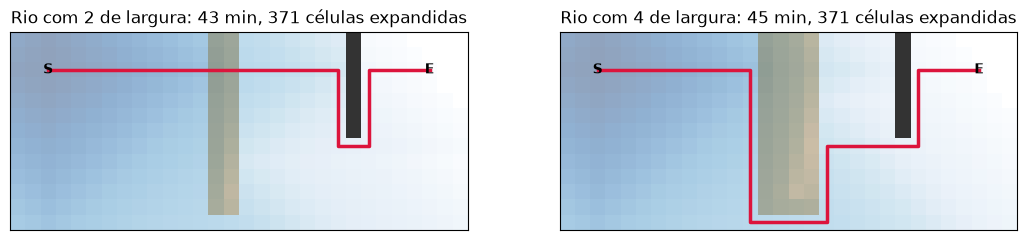

In [14]:
# Executar esta célula

def desenhar_grelha(ax, grelha, ordem=(), cam=(), titulo=""):
    base = np.array([[{"#": 3, "~": 2}.get(ch, 0) for ch in linha] for linha in grelha], dtype=float)
    ax.imshow(base, cmap=ListedColormap(["#ffffff", "#ffffff", "#c8a26b", "#333333"]), vmin=0, vmax=3)
    if ordem:
        explorado = np.full(base.shape, np.nan)
        for k, (r, c) in enumerate(ordem):
            explorado[r, c] = k
        ax.imshow(explorado, cmap="Blues_r", alpha=0.45)
    if cam:
        ys, xs = zip(*cam)
        ax.plot(xs, ys, color="crimson", linewidth=2.5)
    for simbolo in "SE":
        r, c = encontrar(grelha, simbolo)
        ax.text(c, r, simbolo, ha="center", va="center", fontweight="bold")
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])


fig, eixos = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, largura in zip(eixos, (2, 4)):
    grelha = labirinto_rio(largura)
    tempo, cam, ordem = dijkstra_grelha(grelha, encontrar(grelha, "S"), encontrar(grelha, "E"))
    desenhar_grelha(ax, grelha, ordem, cam, f"Rio com {largura} de largura: {tempo} min, {len(ordem)} células expandidas")
plt.show()

O Dijkstra expande em «círculos» à volta da partida, por ordem de custo, sem saber onde fica a saída: explora quase todo o mapa. A secção 6 mostra como o A* usa uma estimativa da distância à saída para explorar muito menos.

### 4.2 O terreno montanhoso: um custo *minimax*

Numa matriz de altitudes, queremos ir do canto superior esquerdo ao inferior direito. O **esforço** de uma rota não é a soma, mas a **maior** diferença de altitude entre duas células consecutivas: um caminhante com uma mochila pesada aguenta muitos passos suaves, mas não um degrau grande. É o mesmo critério *minimax* do problema dos grupos do N3_08.

O Dijkstra continua a funcionar se trocarmos a soma pelo máximo: o novo custo é `max(esforço_atual, |altura_atual - altura_vizinho|)`. A prova da secção 3.4 só precisa de que o custo de um caminho **nunca diminua** quando ele se prolonga, e o máximo também tem essa propriedade.

In [15]:
# Executar esta célula

def esforco_minimo(alturas):
    L, C = alturas.shape
    inicio, fim = (0, 0), (L - 1, C - 1)
    esforco, anterior = {inicio: 0}, {inicio: None}
    fila, fechadas = [(0, inicio)], set()
    while fila:
        e, u = heapq.heappop(fila)
        if u in fechadas:
            continue
        fechadas.add(u)
        if u == fim:
            break
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            v = (u[0] + dr, u[1] + dc)
            if 0 <= v[0] < L and 0 <= v[1] < C:
                novo = max(e, abs(int(alturas[u]) - int(alturas[v])))  # minimax em vez de soma
                if novo < esforco.get(v, math.inf):
                    esforco[v], anterior[v] = novo, u
                    heapq.heappush(fila, (novo, v))
    return esforco[fim], caminho(anterior, fim)


pequeno = np.array([[1, 2, 2], [3, 8, 2], [5, 3, 5]])
e, cam = esforco_minimo(pequeno)
print("Esforço mínimo:", e, "| caminho:", [int(pequeno[c]) for c in cam])

Esforço mínimo: 2 | caminho: [1, 3, 5, 3, 5]


Na matriz pequena, o caminho pelas alturas 1 → 3 → 5 → 3 → 5 tem diferenças de 2 em todos os passos (esforço **2**). O caminho pela direita, 1 → 2 → 2 → 2 → 5, é mais plano no início, mas acaba com um salto de 3.

Num terreno maior, com uma montanha ao centro, comparamos o caminho de **menor esforço máximo** com o caminho de **menor subida total** (o Dijkstra normal, com a soma das diferenças):

Menor esforço máximo: maior degrau 1, subida total 35, 60 passos
Menor subida total:   maior degrau 2, subida total 23, 50 passos


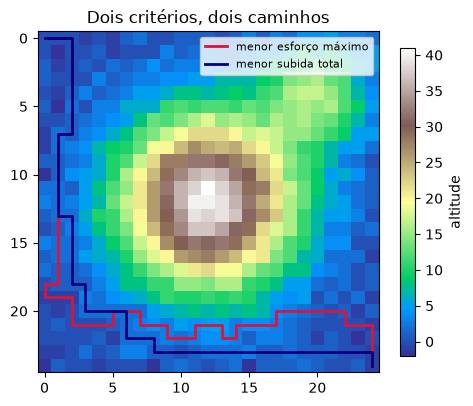

In [16]:
# Executar esta célula

rng = np.random.default_rng(7)
yy, xx = np.mgrid[0:25, 0:25]
terreno = (40 * np.exp(-((yy - 12) ** 2 + (xx - 12) ** 2) / 40) + 15 * np.exp(-((yy - 4) ** 2 + (xx - 20) ** 2) / 15)
           + rng.normal(0, 1, (25, 25))).round().astype(int)

e_minimax, cam_minimax = esforco_minimo(terreno)

grafo_terreno = nx.DiGraph()
for r in range(25):
    for c in range(25):
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            if 0 <= r + dr < 25 and 0 <= c + dc < 25:
                grafo_terreno.add_edge((r, c), (r + dr, c + dc), weight=abs(int(terreno[r, c]) - int(terreno[r + dr, c + dc])))
cam_soma = nx.dijkstra_path(grafo_terreno, (0, 0), (24, 24))


def resumo(cam):
    difs = [abs(int(terreno[a]) - int(terreno[b])) for a, b in zip(cam, cam[1:])]
    return f"maior degrau {max(difs)}, subida total {sum(difs)}, {len(cam) - 1} passos"


print("Menor esforço máximo:", resumo(cam_minimax))
print("Menor subida total:  ", resumo(cam_soma))

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(terreno, cmap="terrain")
for cam, cor, nome in ((cam_minimax, "crimson", "menor esforço máximo"), (cam_soma, "navy", "menor subida total")):
    ys, xs = zip(*cam)
    ax.plot(xs, ys, color=cor, linewidth=2, label=nome)
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Dois critérios, dois caminhos")
fig.colorbar(im, ax=ax, label="altitude", shrink=0.8)
plt.show()

Os dois critérios dão caminhos diferentes. O caminho *minimax* é mais longo e acumula mais subida no total, mas nunca tem um degrau maior do que o mínimo possível. O da soma é mais direto, mas aceita degraus maiores. É a mesma diferença entre «pior grupo» e «soma» do N3_08 (secção 2.3), agora num problema que o Dijkstra resolve exatamente.

## 5. Aumentar o estado

### 5.1 A ideia mais poderosa deste módulo

Muitos problemas parecem exigir um algoritmo novo: «com no máximo K escalas», «com cupões de desconto», «com bateria», «com chaves para abrir portas». Na verdade, quase todos se resolvem com o **mesmo** Dijkstra, mudando apenas o que é um **estado**:

> **Se o caminho tem regras que dependem do que já aconteceu, junta ao estado a informação de que as regras precisam.**

O vértice passa a ser um tuplo como `(cidade, voos_feitos)` ou `(linha, coluna, chaves)`. O grafo destes estados (o **espaço de estados**) é maior do que o original, mas o algoritmo é igual. Nos livros de IA, este Dijkstra sobre estados chama-se **pesquisa de custo uniforme**.

A função seguinte é essa versão genérica. Recebe o estado inicial, uma função que gera os **sucessores** de um estado (pares `(estado, custo)`) e uma função que diz se um estado é objetivo. O parâmetro `heuristica` só será usado na secção 6. Usamos um contador para desempatar na fila, porque os estados podem não ser comparáveis entre si.

In [17]:
# Executar esta célula

def custo_uniforme(inicio, sucessores, e_objetivo, heuristica=None):
    h = heuristica or (lambda estado: 0)
    desempate = itertools.count()
    melhor, anterior = {inicio: 0}, {inicio: None}
    fila, fechados = [(h(inicio), next(desempate), 0, inicio)], set()
    estatisticas = {"expansões": 0, "gerações": 0}
    while fila:
        _, _, g, estado = heapq.heappop(fila)
        if estado in fechados:
            continue
        fechados.add(estado)
        estatisticas["expansões"] += 1
        if e_objetivo(estado):
            return g, caminho(anterior, estado), estatisticas
        for seguinte, custo in sucessores(estado):
            estatisticas["gerações"] += 1
            if seguinte in fechados:  # já expandido: não volta a ser aberto
                continue
            if g + custo < melhor.get(seguinte, math.inf):
                melhor[seguinte], anterior[seguinte] = g + custo, estado
                heapq.heappush(fila, (g + custo + h(seguinte), next(desempate), g + custo, seguinte))
    return -1, None, estatisticas  # objetivo inalcançável

### 5.2 Voos com limite de escalas

Há voos unidirecionais `(origem, destino, preço)`. Queremos ir da cidade 0 à 3 o mais barato possível, mas com **no máximo K escalas** (ou seja, no máximo K + 1 voos).

O Dijkstra normal não serve: guardaria só o caminho mais barato até cada cidade, mesmo que já tenha usado escalas a mais. Um caminho mais caro, mas com menos voos, pode ser o único válido. **Estado:** `(cidade, voos_feitos)`. Um estado com `voos_feitos = K + 1` não tem sucessores.

In [18]:
# Executar esta célula

voos = [(0, 1, 100), (1, 2, 100), (2, 3, 100), (0, 2, 500)]


def sucessores_voos(max_escalas):
    def sucessores(estado):
        cidade, feitos = estado
        if feitos == max_escalas + 1:
            return
        for origem, destino, preco in voos:
            if origem == cidade:
                yield (destino, feitos + 1), preco
    return sucessores


for k in (0, 1, 2):
    custo, cam, est = custo_uniforme((0, 0), sucessores_voos(k), lambda s: s[0] == 3)
    rota = " -> ".join(str(cidade) for cidade, _ in cam) if cam else "impossível"
    print(f"K = {k} escala(s): {custo:4d} | {rota} | {est}")

K = 0 escala(s):   -1 | impossível | {'expansões': 3, 'gerações': 2}
K = 1 escala(s):  600 | 0 -> 2 -> 3 | {'expansões': 5, 'gerações': 4}
K = 2 escala(s):  300 | 0 -> 1 -> 2 -> 3 | {'expansões': 4, 'gerações': 4}


Com K = 1, o caminho barato 0 → 1 → 2 → 3 (300) tem 2 escalas e não é permitido; a resposta é **600** (0 → 2 → 3). Com K = 0 não há voo direto (-1), e com K = 2 o caminho de 300 passa a ser válido.

### 5.3 Cupões de desconto: um grafo em camadas

Com voos `(origem, destino, custo)`, temos **K cupões**: num voo, um cupão reduz o custo para metade (divisão inteira), no máximo um por voo. **Estado:** `(cidade, cupões_usados)`. De cada estado saem duas arestas por voo: sem cupão (mesma «camada») e, se houver cupões, com cupão (camada seguinte). É como empilhar K + 1 cópias do grafo, uma por número de cupões gastos.

In [19]:
# Executar esta célula

voos_cupoes = [(0, 1, 100), (1, 3, 100), (0, 2, 40), (2, 3, 300)]


def sucessores_cupoes(k):
    def sucessores(estado):
        cidade, usados = estado
        for origem, destino, custo in voos_cupoes:
            if origem == cidade:
                yield (destino, usados), custo  # sem cupão
                if usados < k:
                    yield (destino, usados + 1), custo // 2  # com cupão
    return sucessores


for k in (0, 1, 2):
    custo, cam, _ = custo_uniforme((0, 0), sucessores_cupoes(k), lambda s: s[0] == 3)
    print(f"K = {k} cupão(ões): {custo} | estados {cam}")

K = 0 cupão(ões): 200 | estados [(0, 0), (1, 0), (3, 0)]
K = 1 cupão(ões): 150 | estados [(0, 0), (1, 1), (3, 1)]
K = 2 cupão(ões): 100 | estados [(0, 0), (1, 1), (3, 2)]


Sem cupões, a rota mais barata é 0 → 1 → 3 (**200**). Com 1 cupão há duas opções interessantes:

- na rota 0 → 2 → 3, o cupão no voo de 300 dá 40 + 150 = 190;
- na rota 0 → 1 → 3, o cupão num dos voos de 100 dá 100 + 50 = **150**.

O mínimo é **150**. O estado `(1, 1)` no caminho mostra que o cupão foi usado logo no primeiro voo; usá-lo no segundo dava o mesmo custo. Com 2 cupões, os dois voos ficam a metade: **100**.

### 5.4 Carro elétrico com postos de carregamento

Queremos ir da cidade 0 à 3 num carro com bateria de **C = 10 kWh**, que começa cheia. Cada estrada `(u, v, km, horas)` gasta 1 kWh por quilómetro e só se pode fazer com bateria suficiente. Na cidade 1 há um carregador que demora 0,5 h por kWh.

**Estado:** `(cidade, bateria)`. Há duas ações: **viajar** (se houver bateria) e **carregar 1 kWh** (se houver carregador). Carregar de 1 em 1 kWh evita criar uma aresta para cada quantidade possível: a fila de prioridade encadeia sozinha os carregamentos até ao nível certo.

In [20]:
# Executar esta célula

estradas_carro = [(0, 1, 6, 1.0), (1, 2, 6, 1.0), (2, 3, 4, 1.0), (0, 2, 10, 3.5)]
estradas_carro += [(v, u, km, h) for u, v, km, h in estradas_carro]  # bidirecionais
carregadores = {1: 0.5}  # horas por kWh
CAPACIDADE = 10


def sucessores_carro(estado):
    cidade, bateria = estado
    if cidade in carregadores and bateria < CAPACIDADE:
        yield (cidade, bateria + 1), carregadores[cidade]  # carregar 1 kWh
    for u, v, km, horas in estradas_carro:
        if u == cidade and km <= bateria:
            yield (v, bateria - km), horas  # viajar


horas, cam, est = custo_uniforme((0, CAPACIDADE), sucessores_carro, lambda s: s[0] == 3)
print(f"Tempo mínimo: {horas} h | {est}")
print("Estados (cidade, bateria):", cam)

Tempo mínimo: 6.0 h | {'expansões': 19, 'gerações': 19}
Estados (cidade, bateria): [(0, 10), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (2, 4), (3, 0)]


O caminho direto 0 → 2 gasta os 10 kWh e deixa o carro parado na cidade 2, sem carregador. O ótimo é 0 → 1 (1 h, ficam 4 kWh), carregar 6 kWh na cidade 1 (3 h), 1 → 2 (1 h) e 2 → 3 (1 h): **6 horas**. A sequência de estados mostra os seis carregamentos de 1 kWh.

### 5.5 O cofre com chaves, portas e peso

Num labirinto, `a` é uma chave e `A` a porta que ela abre; `~` é lama (3 minutos) e o resto custa 1 minuto. Cada chave que se transporta **pesa**: acrescenta 1 minuto a todos os passos seguintes. A chave `b` abre a porta `B`.

**Estado:** `(linha, coluna, chaves)`, em que `chaves` é uma **máscara de bits**: o bit 0 diz se temos a chave `a`, o bit 1 a chave `b`, etc. Com 2 chaves há $2^2 = 4$ combinações, e o espaço de estados tem $L \times C \times 4$ estados. A mesma célula pode ser visitada mais do que uma vez, com conjuntos de chaves diferentes.

In [21]:
# Executar esta célula

COFRE = [
    "S...~....b",
    ".##.#.###.",
    ".#a.#.....",
    ".####.###.",
    "......#...",
    "####A##B##",
    "E~~~......",
]


def sucessores_cofre(estado):
    r, c, chaves = estado
    for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
        rr, cc = r + dr, c + dc
        if not (0 <= rr < len(COFRE) and 0 <= cc < len(COFRE[0])) or COFRE[rr][cc] == "#":
            continue
        simbolo = COFRE[rr][cc]
        if simbolo in "ABCDF" and not chaves >> (ord(simbolo) - ord("A")) & 1:
            continue  # porta trancada e não temos a chave
        custo = (3 if simbolo == "~" else 1) + bin(chaves).count("1")  # peso das chaves
        novas = chaves | (1 << (ord(simbolo) - ord("a"))) if simbolo in "abcdef" else chaves
        yield (rr, cc, novas), custo


inicio, saida = encontrar(COFRE, "S"), encontrar(COFRE, "E")
minutos, cam, est = custo_uniforme((*inicio, 0), sucessores_cofre, lambda s: (s[0], s[1]) == saida)
print(f"Tempo mínimo: {minutos} min | {est}")
print("Percurso:", " ".join(f"({r},{c}){'+a' if k else ''}" for r, c, k in cam))

Tempo mínimo: 46 min | {'expansões': 142, 'gerações': 295}
Percurso: (0,0) (0,1) (0,2) (0,3) (1,3) (2,3) (2,2)+a (2,3)+a (1,3)+a (0,3)+a (0,4)+a (0,5)+a (1,5)+a (2,5)+a (3,5)+a (4,5)+a (4,4)+a (5,4)+a (6,4)+a (6,3)+a (6,2)+a (6,1)+a (6,0)+a


O percurso ótimo vai buscar a chave `a`, volta atrás pelas mesmas células, agora **com** a chave (são estados diferentes, por isso o Dijkstra não os confunde), abre a porta `A` e atravessa a lama até à saída. A chave `b` fica onde está: apanhá-la só acrescentaria peso, e a porta `B` não leva a um caminho melhor. O tempo mínimo é de **46 minutos**.

O custo deste poder é o tamanho do espaço de estados. Com $K$ chaves, cada célula multiplica-se por $2^K$ estados, e a complexidade passa a ser $O(S \log S)$, com $S = L \times C \times 2^K$. Cada chave a mais **duplica** o espaço de estados: é uma **explosão combinatória**, e a memória esgota-se antes do tempo. Para ter uma ideia, medimos quanta memória ocupa cada estado nos dicionários `melhor` e `anterior` e estimamos o total para o cofre (70 células) e para um mapa de jogo de 100 × 100 células:

In [22]:
# Executar esta célula

import tracemalloc

tracemalloc.start()
amostra_melhor = {(r, c, k): r + c + k for r in range(100) for c in range(100) for k in range(10)}
amostra_anterior = {(r, c, k): (r, c, k) for r in range(100) for c in range(100) for k in range(10)}
bytes_por_estado = tracemalloc.get_traced_memory()[0] / len(amostra_melhor)
tracemalloc.stop()
del amostra_melhor, amostra_anterior
print(f"Memória medida: cerca de {bytes_por_estado:.0f} bytes por estado")


def memoria(estados):
    b = estados * bytes_por_estado
    for unidade in ("B", "KB", "MB", "GB", "TB"):
        if b < 1024:
            return f"{b:.0f} {unidade}"
        b /= 1024
    return f"{b:.0f} PB"


linhas = [{"chaves": k, "estados (cofre, 70 células)": 70 * 2 ** k, "memória (cofre)": memoria(70 * 2 ** k),
           "estados (mapa 100×100)": 10_000 * 2 ** k, "memória (mapa 100×100)": memoria(10_000 * 2 ** k)}
          for k in (1, 2, 6, 10, 16, 20, 30)]
pd.DataFrame(linhas).set_index("chaves")

Memória medida: cerca de 297 bytes por estado


,"estados (cofre, 70 células)",memória (cofre),estados (mapa 100×100),memória (mapa 100×100)
chaves,,,,
1,140,41 KB,20000,6 MB
2,280,81 KB,40000,11 MB
6,4480,1 MB,640000,181 MB
10,71680,20 MB,10240000,3 GB
16,4587520,1 GB,655360000,181 GB
20,73400320,20 GB,10485760000,3 TB
30,75161927680,20 TB,10737418240000,3 PB


Com 6 chaves, tudo cabe folgadamente. Com 20 chaves num mapa de 100 × 100 já seriam milhares de milhões de estados, muito para além da memória de um computador comum, e com 30 chaves nem o cofre pequeno caberia. Na prática, o pior caso raramente se atinge, porque muitas combinações de chaves não são alcançáveis. Mesmo assim, antes de aumentar o estado, vale a pena estimar quantos estados pode haver. Quando são demasiados, há três saídas: guardar só a informação estritamente necessária no estado, usar uma heurística (A*) que evite explorar a maioria deles, ou abdicar da garantia de ótimo com pesquisa local (N3_08).

## 6. A*: pesquisar com uma bússola

### 6.1 A ideia

O Dijkstra expande por ordem do custo **já gasto**, $g(n)$, sem saber onde está o objetivo. O **A\*** (Hart, Nilsson e Raphael, 1968) ordena a fila por

$$f(n) = g(n) + h(n)$$

em que $h(n)$ é uma **heurística**: uma estimativa do custo que falta até ao objetivo. Assim, a pesquisa vai sobretudo na direção certa.

- A heurística é **admissível** se nunca sobrestima o custo real que falta. Com uma heurística admissível, o A* encontra o ótimo.
- É **consistente** se $h(n) \le \text{custo}(n, n') + h(n')$ para cada aresta. Com uma heurística consistente, cada estado só precisa de ser expandido uma vez, e o A* tem a eficiência do Dijkstra no pior caso. Todas as heurísticas consistentes são admissíveis, mas o contrário não é verdade (secção 6.2).
- Com $h = 0$, o A* é exatamente o Dijkstra.

Na grelha do rio, cada passo custa pelo menos 1 minuto, por isso a **distância de Manhattan** até à saída (linhas + colunas) nunca sobrestima o tempo real: é admissível, e também consistente. A nossa `dijkstra_grelha` já aceita uma heurística:

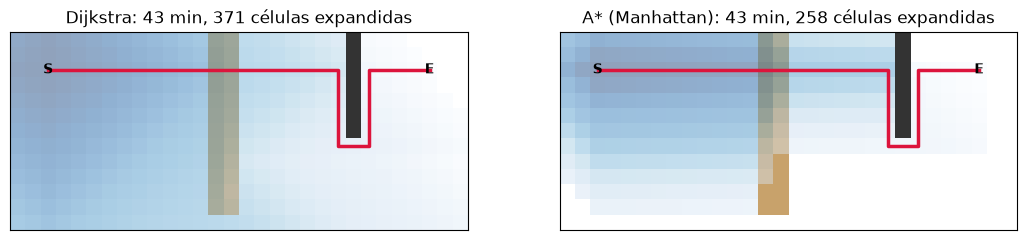

In [23]:
# Executar esta célula

grelha = labirinto_rio(2)
S, E = encontrar(grelha, "S"), encontrar(grelha, "E")


def manhattan(celula):
    return abs(celula[0] - E[0]) + abs(celula[1] - E[1])


fig, eixos = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, (nome, h) in zip(eixos, (("Dijkstra", None), ("A* (Manhattan)", manhattan))):
    tempo, cam, ordem = dijkstra_grelha(grelha, S, E, heuristica=h)
    desenhar_grelha(ax, grelha, ordem, cam, f"{nome}: {tempo} min, {len(ordem)} células expandidas")
plt.show()

Os dois encontram o mesmo tempo mínimo, mas o A* expande menos células (cerca de 30 % menos): concentra-se na faixa entre a partida e a saída. O ganho depende do mapa: aqui, a parede obriga a desviar e reduz a vantagem. Em mapas abertos, a diferença é muito maior. É por isso que o A* é a escolha habitual em navegação e em jogos: quando há **um destino** e uma boa estimativa da distância, poupa trabalho sem perder a garantia de ótimo. O exercício 3 mostra o que acontece quando a heurística deixa de ser admissível.

### 6.2 Admissível, mas inconsistente: reabrir estados

As nossas implementações usam um conjunto de estados **fechados**: depois de expandido, um estado nunca mais é processado. Com uma heurística consistente isso é seguro, porque o primeiro caminho com que um estado é expandido já é o melhor. Com uma heurística **apenas admissível**, não: o A* pode expandir um estado por um caminho caro e só depois encontrar um mais barato. Se o estado não puder ser **reaberto**, esse caminho melhor perde-se.

No grafo abaixo, o caminho ótimo é S → B → A → G (1 + 1 + 5 = 7). A heurística nunca sobrestima (h(B) = 6, e o custo real de B a G é 6), por isso é admissível. Mas não é consistente: h(B) = 6 > custo(B, A) + h(A) = 1 + 0.

In [24]:
# Executar esta célula

grafo_h = {"S": {"A": 4, "B": 1}, "B": {"A": 1}, "A": {"G": 5}, "G": {}}
h_inconsistente = {"S": 0, "A": 0, "B": 6, "G": 0}


def sucessores_h(estado):
    return grafo_h[estado].items()


def a_estrela_com_reabertura(inicio, sucessores, e_objetivo, heuristica):
    melhor, anterior = {inicio: 0}, {inicio: None}
    fila, desempate = [(heuristica(inicio), 0, 0, inicio)], itertools.count(1)
    expansoes = 0
    while fila:
        _, _, g, estado = heapq.heappop(fila)
        if g > melhor[estado]:  # entrada desatualizada; não há conjunto de fechados
            continue
        expansoes += 1
        if e_objetivo(estado):
            return g, caminho(anterior, estado), expansoes
        for seguinte, custo in sucessores(estado):
            if g + custo < melhor.get(seguinte, math.inf):  # também para estados já expandidos: reabre-os
                melhor[seguinte], anterior[seguinte] = g + custo, estado
                heapq.heappush(fila, (g + custo + heuristica(seguinte), next(desempate), g + custo, seguinte))
    return -1, None, expansoes


custo, cam, est = custo_uniforme("S", sucessores_h, lambda s: s == "G", heuristica=h_inconsistente.get)
print(f"Com fechados:   custo {custo} | {' -> '.join(cam)} | {est['expansões']} expansões")
custo, cam, expansoes = a_estrela_com_reabertura("S", sucessores_h, lambda s: s == "G", h_inconsistente.get)
print(f"Com reabertura: custo {custo} | {' -> '.join(cam)} | {expansoes} expansões")
print("Ótimo (networkx):", nx.dijkstra_path_length(nx.DiGraph([(u, v, {"weight": w}) for u, viz in grafo_h.items() for v, w in viz.items()]), "S", "G"))

Com fechados:   custo 9 | S -> A -> G | 4 expansões
Com reabertura: custo 7 | S -> B -> A -> G | 5 expansões
Ótimo (networkx): 7


O A* expande A primeiro, pelo caminho direto de custo 4, porque $f(A) = 4 + 0$ é menor do que $f(B) = 1 + 6$. Quando depois expande B, descobre que A se alcança com custo 2. Com fechados, A já não é processado de novo e o resultado é **9**, que não é ótimo. Com reabertura, A volta à fila, é expandido outra vez e o resultado é **7**.

**Em resumo:** com uma heurística consistente (como a distância de Manhattan numa grelha), um conjunto de fechados é seguro e eficiente. Com uma heurística apenas admissível, é preciso permitir reabrir estados (como na segunda versão), à custa de expansões repetidas. Felizmente, as heurísticas mais usadas, como as distâncias em linha reta ou de Manhattan, são consistentes.

### 6.3 Pesquisa bidirecional

Quando há **um** destino, podemos pesquisar ao mesmo tempo a partir da origem (para a frente) e a partir do destino (para trás, seguindo as arestas ao contrário), e parar quando as duas pesquisas se encontram. A intuição: em vez de um «círculo» grande de raio $d$ à volta da origem, exploram-se dois círculos de raio $d/2$.

O ganho depende da forma do espaço:

- numa **árvore** com fator de ramificação $b$ (o caso típico dos espaços de estados), uma pesquisa até à profundidade $d$ visita cerca de $b^d$ estados; duas pesquisas até $d/2$ visitam cerca de $2 b^{d/2}$, um ganho **exponencial**;
- numa **grelha** 2D, o número de células a uma distância até $d$ cresce como $d^2$, e dois círculos de raio $d/2$ têm cerca de **metade** da área de um círculo de raio $d$.

Há dois cuidados na implementação:

- **Arestas ao contrário:** na grelha, o custo de uma aresta é o custo de **entrar** na célula de destino. Na pesquisa para trás, ao passar de `u` para o vizinho `v`, a aresta real é `v → u`, que custa entrar em `u`.
- **Critério de paragem:** não basta parar no primeiro encontro, porque esse ponto de encontro pode não estar no caminho ótimo. Guarda-se o melhor custo total $\mu$ visto nos encontros, e para-se quando a soma dos mínimos das duas filas já não pode baixar $\mu$.

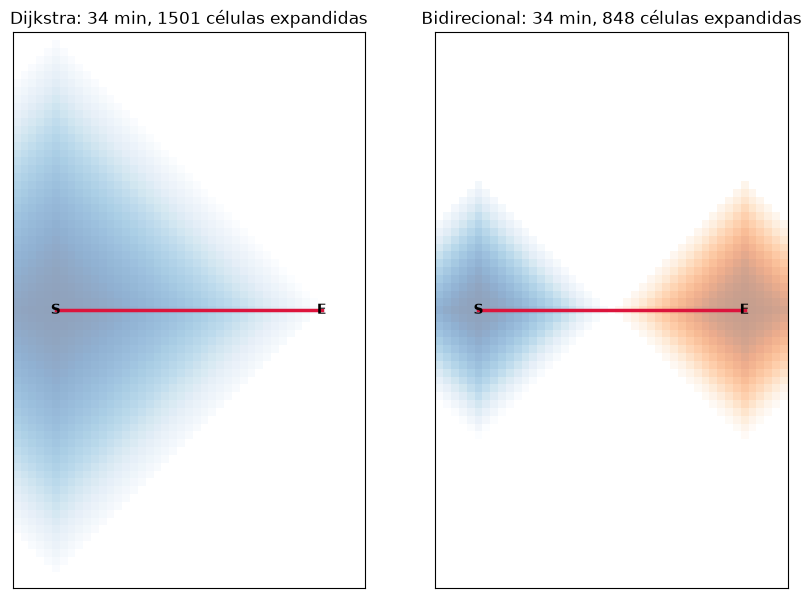

Labirinto do rio: bidirecional 43 min com 363 células expandidas (Dijkstra: 371)


In [25]:
# Executar esta célula

def dijkstra_bidirecional(grelha, inicio, fim):
    custo = lambda celula: CUSTO_CELULA[grelha[celula[0]][celula[1]]]
    dist, anterior = [{inicio: 0}, {fim: 0}], [{inicio: None}, {fim: None}]
    filas, fechadas, ordem = [[(0, inicio)], [(0, fim)]], [set(), set()], [[], []]
    mu, encontro = math.inf, None
    while filas[0] and filas[1]:
        if filas[0][0][0] + filas[1][0][0] >= mu:  # nenhum caminho por expandir pode baixar mu
            break
        lado = 0 if filas[0][0][0] <= filas[1][0][0] else 1  # expandir a fila mais «barata»
        d, u = heapq.heappop(filas[lado])
        if u in fechadas[lado]:
            continue
        fechadas[lado].add(u)
        ordem[lado].append(u)
        for v in vizinhos_grelha(grelha, *u):
            nd = d + (custo(v) if lado == 0 else custo(u))  # para trás, a aresta é v -> u
            if nd < dist[lado].get(v, math.inf):
                dist[lado][v], anterior[lado][v] = nd, u
                heapq.heappush(filas[lado], (nd, v))
            if v in dist[1 - lado] and dist[lado][v] + dist[1 - lado][v] < mu:  # encontro
                mu, encontro = dist[lado][v] + dist[1 - lado][v], v
    if encontro is None:
        return -1, None, ordem
    frente = caminho(anterior[0], encontro)
    tras = caminho(anterior[1], encontro)[::-1][1:]  # do encontro até ao fim
    return mu, frente + tras, ordem


campo = ["." * 45 for _ in range(71)]  # campo aberto, alto o suficiente para os «círculos» não baterem nos limites
campo[35] = campo[35][:5] + "S" + campo[35][6:39] + "E" + campo[35][40:]
S_c, E_c = encontrar(campo, "S"), encontrar(campo, "E")

fig, eixos = plt.subplots(1, 2, figsize=(10, 7.5))
tempo, cam, ordem = dijkstra_grelha(campo, S_c, E_c)
desenhar_grelha(eixos[0], campo, ordem, cam, f"Dijkstra: {tempo} min, {len(ordem)} células expandidas")
tempo_b, cam_b, (ordem_f, ordem_t) = dijkstra_bidirecional(campo, S_c, E_c)
desenhar_grelha(eixos[1], campo, ordem_f, cam_b, f"Bidirecional: {tempo_b} min, {len(ordem_f) + len(ordem_t)} células expandidas")
explorado_tras = np.full((len(campo), len(campo[0])), np.nan)
for k, (r, c) in enumerate(ordem_t):
    explorado_tras[r, c] = k
eixos[1].imshow(explorado_tras, cmap="Oranges_r", alpha=0.45)
plt.show()

grelha = labirinto_rio(2)
tempo_r, _, (of, ot) = dijkstra_bidirecional(grelha, encontrar(grelha, "S"), encontrar(grelha, "E"))
print(f"Labirinto do rio: bidirecional {tempo_r} min com {len(of) + len(ot)} células expandidas "
      f"(Dijkstra: {len(dijkstra_grelha(grelha, encontrar(grelha, 'S'), encontrar(grelha, 'E'))[2])})")

No campo aberto, as duas pesquisas (azul a partir de S, laranja a partir de E) encontram-se a meio, e o total de células expandidas cai para pouco mais de metade, perto do previsto para uma grelha (a pesquisa só a partir de S também perde algumas células, cortadas pelo limite esquerdo do mapa). No labirinto do rio quase não há ganho: o mapa é pequeno e limitado, e as duas pesquisas acabam por cobrir quase tudo à mesma. Como sempre, a vantagem depende da forma do espaço.

A pesquisa bidirecional exige conhecer o **estado objetivo** (para pesquisar a partir dele) e saber gerar **predecessores**, o que nem sempre é possível: no cofre da secção 5.5, por exemplo, não sabemos com que chaves se chega à saída. Combinar a pesquisa bidirecional com o A* também é possível, mas o critério de paragem é mais delicado.

### 6.4 IDA*: o A* com pouca memória

O ponto fraco do A* é a **memória**: guarda todos os estados gerados (nos dicionários `melhor` e `anterior` e na fila), e em espaços grandes isso esgota a memória antes do tempo (secção 5.5). O **IDA\*** (*iterative deepening A\**, Korf, 1985) troca memória por tempo:

1. faz uma pesquisa **em profundidade** que corta os ramos com $f(n) = g(n) + h(n)$ acima de um **limite**;
2. se não encontrar o objetivo, aumenta o limite para o menor $f$ que ultrapassou o limite anterior, e recomeça.

Como é uma pesquisa em profundidade, só guarda o **caminho atual**: a memória é $O(d)$, em que $d$ é a profundidade da solução. Com uma heurística admissível, o primeiro objetivo encontrado é ótimo, tal como no A*. O preço é **repetir trabalho**: cada iteração volta a expandir os estados das iterações anteriores, e sem memória não deteta estados repetidos por caminhos diferentes.

O exemplo clássico é o **puzzle de deslizar** (8-puzzle em 3 × 3, 15-puzzle em 4 × 4): peças numeradas e um espaço vazio (0); cada jogada desliza uma peça para o espaço; o objetivo é pô-las por ordem. A heurística é a soma das distâncias de Manhattan de cada peça à sua posição final, que é admissível e consistente (cada jogada move uma peça uma casa).

In [26]:
# Executar esta célula

def objetivo_puzzle(n):
    return tuple(list(range(1, n * n)) + [0])


def jogadas(estado, n):
    vazio = estado.index(0)
    r, c = divmod(vazio, n)
    for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
        if 0 <= r + dr < n and 0 <= c + dc < n:
            k = (r + dr) * n + (c + dc)
            novo = list(estado)
            novo[vazio], novo[k] = novo[k], novo[vazio]
            yield tuple(novo)


def manhattan_puzzle(estado, n):
    return sum(abs(i // n - (v - 1) // n) + abs(i % n - (v - 1) % n) for i, v in enumerate(estado) if v)


def a_estrela_puzzle(inicio, n):
    objetivo, desempate = objetivo_puzzle(n), itertools.count()
    melhor, fila, fechados, expansoes = {inicio: 0}, [(manhattan_puzzle(inicio, n), 0, 0, inicio)], set(), 0
    while fila:
        _, _, g, s = heapq.heappop(fila)
        if s in fechados:
            continue
        fechados.add(s)
        expansoes += 1
        if s == objetivo:
            return g, expansoes, len(melhor)  # len(melhor): estados guardados em memória
        for t in jogadas(s, n):
            if t not in fechados and g + 1 < melhor.get(t, math.inf):
                melhor[t] = g + 1
                heapq.heappush(fila, (g + 1 + manhattan_puzzle(t, n), next(desempate), g + 1, t))


def ida_estrela_puzzle(inicio, n):
    objetivo = objetivo_puzzle(n)
    caminho_atual, contagem = [inicio], {"expansões": 0, "iterações": 0}

    def profundidade(g, limite):
        s = caminho_atual[-1]
        f = g + manhattan_puzzle(s, n)
        if f > limite:
            return f  # corta, e devolve o f que excedeu o limite
        if s == objetivo:
            return "encontrado"
        contagem["expansões"] += 1
        proximo_limite = math.inf
        for t in jogadas(s, n):
            if len(caminho_atual) > 1 and t == caminho_atual[-2]:
                continue  # não desfazer a última jogada
            caminho_atual.append(t)
            r = profundidade(g + 1, limite)
            if r == "encontrado":
                return r
            proximo_limite = min(proximo_limite, r)
            caminho_atual.pop()
        return proximo_limite

    limite = manhattan_puzzle(inicio, n)
    while True:
        contagem["iterações"] += 1
        r = profundidade(0, limite)
        if r == "encontrado":
            return len(caminho_atual) - 1, contagem
        limite = r


def baralhar(n, jogadas_aleatorias, semente):
    rnd, estado, anterior = random.Random(semente), objetivo_puzzle(n), None
    for _ in range(jogadas_aleatorias):
        opcoes = [t for t in jogadas(estado, n) if t != anterior]
        anterior, estado = estado, rnd.choice(opcoes)
    return estado


linhas = []
for nome, n, semente, baralho in (("8-puzzle", 3, 1, 200), ("15-puzzle", 4, 3, 60)):
    inicio = baralhar(n, baralho, semente)
    sol_a, exp_a, guardados = a_estrela_puzzle(inicio, n)
    sol_i, cont = ida_estrela_puzzle(inicio, n)
    linhas.append({"puzzle": nome, "jogadas (ótimo)": sol_a, "A*: expansões": exp_a, "A*: estados em memória": guardados,
                   "IDA*: jogadas": sol_i, "IDA*: expansões": cont["expansões"], "IDA*: iterações": cont["iterações"],
                   "IDA*: estados em memória": sol_i + 1})
pd.DataFrame(linhas).set_index("puzzle")

,jogadas (ótimo),A*: expansões,A*: estados em memória,IDA*: jogadas,IDA*: expansões,IDA*: iterações,IDA*: estados em memória
puzzle,,,,,,,
8-puzzle,24,2206,3429,24,2711,5,25
15-puzzle,40,212045,410356,40,382337,6,41


Os dois encontram soluções com o mesmo número mínimo de jogadas. No 15-puzzle, o A* guarda centenas de milhares de estados, enquanto o IDA* guarda apenas o caminho atual (dezenas de estados), à custa de expandir mais estados no total, porque repete as iterações anteriores. Em puzzles mais difíceis (o 15-puzzle mais difícil precisa de 80 jogadas), o A* esgota a memória e o IDA* continua a funcionar: foi com ele que Korf resolveu instâncias aleatórias do 15-puzzle pela primeira vez.

## 7. Bellman-Ford: quando há pesos negativos

### 7.1 O algoritmo

O **Bellman-Ford** abdica da escolha gulosa do Dijkstra. Em vez disso, **relaxa todas as arestas**, $V - 1$ vezes. Um caminho mais curto sem ciclos tem no máximo $V - 1$ arestas, e cada ronda garante mais uma aresta certa. Funciona com pesos negativos, e uma ronda extra **deteta ciclos negativos**: se alguma distância ainda baixar na ronda $V$, há um ciclo cujo custo total é negativo, e então o «caminho mais curto» não existe (pode dar-se voltas ao ciclo indefinidamente). O preço é o tempo: $O(V \cdot E)$, muito mais lento do que o Dijkstra.

### 7.2 Arbitragem de moedas

Um uso clássico é detetar **arbitragem**: uma sequência de câmbios que começa e acaba na mesma moeda com lucro. Se trocarmos ao câmbio $r_1$, depois $r_2$, depois $r_3$, ficamos com $r_1 r_2 r_3$ vezes o valor inicial. Há lucro se o produto for maior do que 1. Com os pesos $-\log r$, o produto passa a soma ($-\log r_1 - \log r_2 - \log r_3$), e «produto maior do que 1» passa a «soma negativa»: **uma oportunidade de arbitragem é um ciclo negativo**. As taxas abaixo são **fictícias**, escolhidas para haver uma oportunidade.

In [27]:
# Executar esta célula

taxas = {("EUR", "USD"): 1.08, ("USD", "JPY"): 151.0, ("JPY", "EUR"): 0.0063, ("EUR", "GBP"): 0.85,
         ("GBP", "USD"): 1.26, ("USD", "EUR"): 0.92, ("GBP", "EUR"): 1.17, ("JPY", "USD"): 0.0066}


def bellman_ford(vertices, arestas, origem):
    dist = {v: math.inf for v in vertices}
    anterior = {v: None for v in vertices}
    dist[origem] = 0
    for _ in range(len(vertices) - 1):
        for u, v, w in arestas:
            if dist[u] + w < dist[v]:
                dist[v], anterior[v] = dist[u] + w, u
    for u, v, w in arestas:  # ronda extra: se ainda melhora, há ciclo negativo
        if dist[u] + w < dist[v]:
            anterior[v] = u
            x = v
            for _ in range(len(vertices)):  # recuar V passos garante cair dentro do ciclo
                x = anterior[x]
            ciclo, y = [x], anterior[x]
            while y != x:
                ciclo.append(y)
                y = anterior[y]
            ordem = ciclo[::-1]  # pela ordem dos câmbios
            return dist, ordem + [ordem[0]]
    return dist, None


moedas = sorted({m for par in taxas for m in par})
arestas = [(a, b, -math.log(r)) for (a, b), r in taxas.items()]
_, ciclo = bellman_ford(moedas, arestas, "EUR")
lucro = math.prod(taxas[(a, b)] for a, b in zip(ciclo, ciclo[1:]))
print("Ciclo de arbitragem:", " -> ".join(ciclo), f"| 1 unidade vira {lucro:.4f} ({lucro - 1:+.1%})")
print("networkx também deteta um ciclo negativo:",
      nx.negative_edge_cycle(nx.DiGraph([(a, b, {"weight": w}) for a, b, w in arestas])))

Ciclo de arbitragem: USD -> JPY -> EUR -> USD | 1 unidade vira 1.0274 (+2.7%)
networkx também deteta um ciclo negativo: True


### 7.3 Que algoritmo escolher?

| | Dijkstra | A* | Bellman-Ford |
| --- | --- | --- | --- |
| Pesos negativos | não suporta | não suporta | suporta e deteta ciclos negativos |
| Objetivo | de uma origem para **todos** os vértices (ou um destino) | de uma origem para **um** destino | de uma origem para todos os vértices |
| Heurística | não usa | $f(n) = g(n) + h(n)$, com $h$ admissível | não usa |
| Tempo | $O((V + E) \log V)$ com `heapq` | igual ao Dijkstra no pior caso (com $h$ consistente); na prática, muito menos expansões | $O(V \cdot E)$ |
| Usos típicos | redes rodoviárias e de comunicações, latência, grafos sem coordenadas | jogos, navegação ponto a ponto, labirintos | finanças (arbitragem), custos com bónus ou reembolsos |

**Em resumo:**

- há arestas com peso negativo → **Bellman-Ford**;
- todos os pesos são ≥ 0 e quero as distâncias para todos os vértices, ou não tenho forma de estimar a distância ao destino → **Dijkstra**;
- todos os pesos são ≥ 0, há um só destino e uma estimativa admissível da distância → **A\***;
- o problema tem regras que dependem do passado → **aumentar o estado** e usar qualquer um dos anteriores sobre o espaço de estados.

## 8. Todos os pares: Floyd-Warshall e Johnson

### 8.1 Floyd-Warshall

O Dijkstra e o Bellman-Ford calculam distâncias **a partir de uma origem**. Às vezes queremos a distância entre **todos os pares** de vértices, como na tabela de distâncias de um atlas rodoviário. Podemos correr um Dijkstra a partir de cada vértice, mas há um algoritmo clássico mais simples, o **Floyd-Warshall**: para cada vértice $k$, verifica se passar por $k$ encurta o caminho entre cada par $(i, j)$.

$$d_{ij} \leftarrow \min(d_{ij},\; d_{ik} + d_{kj})$$

Depois de considerar os vértices $1, \dots, k$ como intermediários, $d_{ij}$ é o caminho mais curto que só passa por esses vértices. São três ciclos encaixados: $O(V^3)$ em tempo e $O(V^2)$ em memória, independentemente do número de arestas. Funciona com pesos negativos (desde que não haja ciclos negativos, que se detetam por um $d_{ii} < 0$).

In [28]:
# Executar esta célula

def floyd_warshall(vertices, arestas):
    d = {u: {v: (0 if u == v else math.inf) for v in vertices} for u in vertices}
    for u, v, w in arestas:
        d[u][v] = min(d[u][v], w)
    for k in vertices:  # passar por k ajuda?
        for i in vertices:
            if d[i][k] == math.inf:
                continue
            for j in vertices:
                if d[i][k] + d[k][j] < d[i][j]:
                    d[i][j] = d[i][k] + d[k][j]
    return d


cidades = list(estradas)
arestas_estradas = [(a, b, w) for a in estradas for b, w in estradas[a].items()]
atlas = floyd_warshall(cidades, arestas_estradas)
pd.DataFrame(atlas).loc[cidades, cidades].astype(int)

,Porto,Coimbra,Viseu,Lisboa,Castelo Branco,Évora,Faro
Porto,0,15,20,40,32,54,74
Coimbra,15,0,30,25,18,39,59
Viseu,20,30,0,48,12,34,54
Lisboa,40,25,48,0,36,14,34
Castelo Branco,32,18,12,36,0,22,42
Évora,54,39,34,14,22,0,20
Faro,74,59,54,34,42,20,0


É a tabela de custos mínimos entre todas as cidades do exemplo Porto → Faro: a linha Porto, coluna Faro, dá os mesmos 74 € do Dijkstra.

### 8.2 Johnson: Bellman-Ford uma vez, Dijkstra muitas vezes

Em grafos **esparsos** (poucas arestas por vértice), correr um Dijkstra a partir de cada vértice custa $O(V (V + E) \log V)$, muito menos do que $O(V^3)$. O problema são os pesos negativos, que o Dijkstra não aceita. O **algoritmo de Johnson** (1977) resolve isto com um truque elegante, que é a ponte entre o Bellman-Ford e o Dijkstra:

1. acrescenta um vértice auxiliar $q$ ligado a todos os vértices com peso 0, e corre **um** Bellman-Ford a partir de $q$, obtendo um «potencial» $h(v)$ para cada vértice (e detetando ciclos negativos);
2. **repondera** cada aresta: $w'(u, v) = w(u, v) + h(u) - h(v)$. Como $h(v) \le h(u) + w(u, v)$ (é uma distância mínima), todos os novos pesos são $\ge 0$;
3. corre um **Dijkstra** a partir de cada vértice com os pesos novos;
4. corrige as distâncias: $d(u, v) = d'(u, v) - h(u) + h(v)$.

A reponderação não muda qual é o caminho mais curto: num caminho de $u$ a $v$, os termos $h$ intermédios cancelam-se, e todos os caminhos entre os mesmos extremos mudam pela mesma quantidade, $h(u) - h(v)$.

In [29]:
# Executar esta célula

def johnson(vertices, arestas):
    q = object()  # vértice auxiliar, diferente de todos os outros
    h, ciclo = bellman_ford(vertices + [q], arestas + [(q, v, 0) for v in vertices], q)
    if ciclo:
        raise ValueError("O grafo tem um ciclo negativo")
    reponderado = {u: {} for u in vertices}
    for u, v, w in arestas:
        reponderado[u][v] = min(reponderado[u].get(v, math.inf), w + h[u] - h[v])  # >= 0
    distancias = {}
    for u in vertices:
        d, _, _ = dijkstra(reponderado, u)
        distancias[u] = {v: d[v] - h[u] + h[v] for v in vertices}
    return distancias


# Grafo com pesos negativos mas sem ciclos negativos: pesos positivos alterados por um «potencial» aleatório
rnd = random.Random(0)
vertices = list("ABCDEFGH")
potencial = {v: rnd.randint(-10, 10) for v in vertices}
arestas_neg = [(u, v, rnd.randint(1, 9) + potencial[u] - potencial[v])
               for u in vertices for v in rnd.sample(vertices, 3) if u != v]
print("Arestas com peso negativo:", sum(w < 0 for _, _, w in arestas_neg), "de", len(arestas_neg))

d_johnson = johnson(vertices, arestas_neg)
d_floyd = floyd_warshall(vertices, arestas_neg)
G_neg = nx.DiGraph()
G_neg.add_weighted_edges_from(arestas_neg)
d_nx = dict(nx.johnson(G_neg))
iguais = all(d_johnson[u][v] == d_floyd[u][v] for u in vertices for v in vertices)
print("Johnson = Floyd-Warshall:", iguais)
print("Confere com networkx (pares alcançáveis):",
      all(math.isclose(d_johnson[u][v], sum(G_neg[a][b]["weight"] for a, b in zip(cam, cam[1:])))
          for u, caminhos in d_nx.items() for v, cam in caminhos.items()))
pd.DataFrame(d_johnson).T.loc[vertices, vertices].map(lambda x: "∞" if x == math.inf else int(x))

Arestas com peso negativo: 5 de 20
Johnson = Floyd-Warshall: True
Confere com networkx (pares alcançáveis): True


,A,B,C,D,E,F,G,H
A,0,7,20,15,-1,∞,∞,7
B,10,0,30,18,2,∞,∞,17
C,-5,-6,0,7,-9,∞,∞,-6
D,2,5,22,0,-1,∞,∞,5
E,18,16,38,16,0,∞,∞,16
F,5,12,25,16,0,0,∞,12
G,6,13,26,10,0,∞,0,13
H,10,0,30,13,-3,∞,∞,0


Os três cálculos coincidem. Para ver quando cada um compensa, medimos o tempo em grafos aleatórios esparsos (4 arestas por vértice) de tamanho crescente:

In [30]:
# Executar esta célula

linhas = []
for n in (50, 100, 200, 300):
    rnd = random.Random(1)
    vs = list(range(n))
    pot = {v: rnd.randint(-10, 10) for v in vs}
    ars = [(u, v, rnd.randint(1, 9) + pot[u] - pot[v]) for u in vs for v in rnd.sample(vs, 4) if u != v]
    t0 = time.process_time()
    floyd_warshall(vs, ars)
    t1 = time.process_time()
    johnson(vs, ars)
    t2 = time.process_time()
    linhas.append({"vértices": n, "arestas": len(ars), "Floyd-Warshall (s)": round(t1 - t0, 2), "Johnson (s)": round(t2 - t1, 2)})
pd.DataFrame(linhas).set_index("vértices")

,arestas,Floyd-Warshall (s),Johnson (s)
vértices,,,
50,194,0.01,0.01
100,395,0.05,0.01
200,792,0.40,0.06
300,1198,1.44,0.14


Em grafos esparsos, o Johnson ganha, e a vantagem cresce com o tamanho: o Floyd-Warshall é $O(V^3)$ seja qual for o número de arestas, enquanto o Johnson é $O(V \cdot E + V (V + E) \log V)$. Em grafos **densos** (com $E$ perto de $V^2$), a vantagem do Johnson desaparece, porque $O(V \cdot E)$ já é $O(V^3)$, e o Floyd-Warshall, com muito menos código, é normalmente o preferido.

| | Uma origem | Todos os pares |
| --- | --- | --- |
| Pesos ≥ 0 | Dijkstra (ou A* para um destino) | Dijkstra a partir de cada vértice; Floyd-Warshall se o grafo for denso |
| Pesos negativos | Bellman-Ford | Johnson (esparso) ou Floyd-Warshall (denso) |

## 9. Para saber mais: o Dijkstra é ótimo?

### 9.1 A barreira da ordenação

O Dijkstra devolve os vértices **por ordem** de distância à origem: é, no fundo, uma ordenação. E ordenar $n$ elementos por comparações exige, no pior caso, cerca de $n \log_2 n$ comparações. Durante décadas, o tempo $O(m + n \log n)$ do Dijkstra (com as melhores filas de prioridade) foi visto como o melhor possível: a chamada **barreira da ordenação**.

Podemos ver esta ordem de grandeza na prática, contando as comparações que o `heapq` faz em grafos aleatórios com 4 arestas por vértice:

In [31]:
# Executar esta célula

class Entrada:
    comparacoes = 0
    __slots__ = ("d", "v")

    def __init__(self, d, v):
        self.d, self.v = d, v

    def __lt__(self, outra):
        Entrada.comparacoes += 1
        return self.d < outra.d


linhas = []
for n in (1_000, 4_000, 16_000, 64_000):
    rnd = random.Random(1)
    g = {v: {rnd.randrange(n): rnd.random() for _ in range(4)} for v in range(n)}
    Entrada.comparacoes = 0
    dist, fila, fechados = {0: 0.0}, [Entrada(0.0, 0)], set()
    while fila:
        e = heapq.heappop(fila)
        if e.v in fechados:
            continue
        fechados.add(e.v)
        for w, p in g[e.v].items():
            if e.d + p < dist.get(w, math.inf):
                dist[w] = e.d + p
                heapq.heappush(fila, Entrada(dist[w], w))
    linhas.append({"vértices": n, "comparações": Entrada.comparacoes,
                   "n·log2(n)": round(n * math.log2(n)), "razão": round(Entrada.comparacoes / (n * math.log2(n)), 2)})
pd.DataFrame(linhas).set_index("vértices")

,comparações,n·log2(n),razão
vértices,,,
1000,13369,9966,1.34
4000,62926,47863,1.31
16000,293930,223453,1.32
64000,1346809,1021810,1.32


A razão entre as comparações e $n \log_2 n$ mantém-se praticamente constante: o trabalho da fila de prioridade cresce como uma ordenação.

### 9.2 O resultado de 2025

Em 2025, Ran Duan e colegas (Universidade de Tsinghua, Universidade de Stanford e Instituto Max Planck de Informática) apresentaram um algoritmo determinístico para caminhos mais curtos a partir de uma origem, em grafos **dirigidos** com pesos reais **não negativos**, que corre em $O(m \log^{2/3} n)$. É o primeiro a bater o limite do Dijkstra em grafos esparsos, e ganhou o prémio de melhor artigo do STOC 2025. A ideia central é **não ordenar a fronteira toda**: o algoritmo combina passos do Dijkstra com passos do Bellman-Ford numa recursão que reduz o número de vértices que é preciso ordenar, com uma estrutura de dados que insere e retira vértices em lotes.

Quanto se ganha? Sem contar as constantes:

| Vértices | $\log_2 n$ | $\log_2^{2/3} n$ |
| --- | --- | --- |
| mil | ≈ 10 | ≈ 4,6 |
| um milhão | ≈ 20 | ≈ 7,3 |
| mil milhões | ≈ 30 | ≈ 9,6 |

Mesmo com mil milhões de vértices, o fator ganho é inferior a 4, antes de contar as constantes, que neste algoritmo são grandes. É um resultado teórico importante (mostra que o Dijkstra **não** é o melhor possível para calcular distâncias), mas não substitui, na prática, um bom Dijkstra.

### 9.3 Uma subtileza: depende da pergunta

Pouco antes, em 2023-2024, Haeupler, Hladík, Rozhoň, Tarjan e Tětek mostraram que o Dijkstra, com uma fila de prioridade adequada, é **universalmente ótimo** para o problema de devolver os vértices **por ordem** de distância. Os dois resultados não se contradizem: se só queremos as **distâncias**, dá para fazer melhor do que o Dijkstra; se queremos também a **ordem**, o Dijkstra (bem implementado) já é o melhor possível. Na teoria dos algoritmos, a resposta a «qual é o melhor algoritmo?» depende sempre da pergunta exata.

## 10. Experimenta

### Exercício 1 – Partir paredes

Na grelha abaixo, cada passo custa 1 minuto, mas temos uma picareta que permite atravessar no máximo **K** paredes (`#`), também a 1 minuto cada. Define o estado e os sucessores e usa a `custo_uniforme` para calcular o tempo mínimo de `S` a `E` com K = 0, 1 e 2.

```text
S...#.....
.##.#.###.
.#..#...#.
.#.##.#.#.
.#....#.#.
.######.#.
........#E
```

In [32]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

O estado passa a ser `(linha, coluna, paredes_partidas)`; entrar numa parede só é possível se ainda não se partiram K.

```python
PAREDES = [
    "S...#.....",
    ".##.#.###.",
    ".#..#...#.",
    ".#.##.#.#.",
    ".#....#.#.",
    ".######.#.",
    "........#E",
]


def sucessores_paredes(k):
    def sucessores(estado):
        r, c, partidas = estado
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            rr, cc = r + dr, c + dc
            if 0 <= rr < len(PAREDES) and 0 <= cc < len(PAREDES[0]):
                if PAREDES[rr][cc] != "#":
                    yield (rr, cc, partidas), 1
                elif partidas < k:
                    yield (rr, cc, partidas + 1), 1
    return sucessores


inicio, saida = encontrar(PAREDES, "S"), encontrar(PAREDES, "E")
for k in (0, 1, 2):
    minutos, cam, est = custo_uniforme((*inicio, 0), sucessores_paredes(k), lambda s: (s[0], s[1]) == saida)
    print(f"K = {k}: {minutos} min | {est}")
```

Sem picareta, o caminho dá a volta pelo labirinto: **25** minutos. Com uma parede, basta partir a parede junto à saída (na última linha) e seguir pela esquerda e por baixo: **15** minutos. Uma segunda parede não ajuda, porque 15 já é o comprimento do caminho mais direto possível (a distância de Manhattan entre S e E).

</details>

### Exercício 2 – O caminho mais fiável

Numa rede, cada ligação funciona com uma certa probabilidade. A fiabilidade de um caminho é o **produto** das probabilidades das suas ligações. Encontra o caminho mais fiável de A a D. Dica: maximizar um produto de probabilidades é o mesmo que minimizar a soma de $-\log p$, e $-\log p \ge 0$, por isso o Dijkstra serve (como na arbitragem, mas sem pesos negativos).

```python
fiabilidade = {("A", "B"): 0.9, ("A", "C"): 0.95, ("B", "D"): 0.95, ("C", "D"): 0.8,
               ("C", "E"): 0.9, ("E", "D"): 0.97, ("B", "E"): 0.99}  # ligações nos dois sentidos
```

In [33]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
fiabilidade = {("A", "B"): 0.9, ("A", "C"): 0.95, ("B", "D"): 0.95, ("C", "D"): 0.8,
               ("C", "E"): 0.9, ("E", "D"): 0.97, ("B", "E"): 0.99}

rede_fiavel = {}
for (a, b), p in fiabilidade.items():
    rede_fiavel.setdefault(a, {})[b] = -math.log(p)
    rede_fiavel.setdefault(b, {})[a] = -math.log(p)

dist, anterior, _ = dijkstra(rede_fiavel, "A")
cam = caminho(anterior, "D")
print(" -> ".join(cam), f"| fiabilidade {math.exp(-dist['D']):.4f}")
```

O caminho mais fiável é **A → B → E → D**, com fiabilidade 0,9 × 0,99 × 0,97 ≈ **0,864**. É mais longo do que A → B → D (0,855) ou A → C → D (0,76), mas cada ligação é mais segura.

</details>

### Exercício 3 – Uma heurística que exagera

No labirinto `labirinto_rio(4)`, corre o A* com a heurística de Manhattan multiplicada por 1 e por 3. Compara o tempo do caminho encontrado e o número de células expandidas. A heurística multiplicada por 3 é admissível? O que se ganha e o que se perde?

In [34]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
grelha4 = labirinto_rio(4)
S4, E4 = encontrar(grelha4, "S"), encontrar(grelha4, "E")
for fator in (1, 3):
    h = lambda celula, f=fator: f * (abs(celula[0] - E4[0]) + abs(celula[1] - E4[1]))
    tempo, cam, ordem = dijkstra_grelha(grelha4, S4, E4, heuristica=h)
    custo_real = sum(CUSTO_CELULA[grelha4[r][c]] for r, c in cam[1:])
    print(f"Manhattan x {fator}: caminho de {custo_real} min | {len(ordem)} células expandidas")
```

Com o fator 3, a heurística **sobrestima** o custo que falta (não é admissível): o A* expande muito menos células, mas devolve um caminho pior (51 minutos em vez de 45), porque atravessa a lama em vez de dar a volta. É um compromisso usado na prática (*weighted A\**) quando a rapidez importa mais do que o ótimo exato, mas perde-se a garantia de ótimo.

</details>

## Verifica o que aprendeste

1. Como se representa um grafo com pesos numa lista de adjacência em Python?
2. Porque é que o Dijkstra pode fixar a distância do vértice mais próximo ainda não visitado? Que condição sobre os pesos é necessária?
3. Porque é que a implementação com `heapq` pode ter entradas repetidas na fila, e porque é que isso não dá resultados errados?
4. No exemplo Porto → Faro, porque é que o Dijkstra devolveu só uma das duas rotas ótimas? Como se obtêm todas?
5. Porque é que o tempo de chegada do sinal a todos os servidores é a **maior** das distâncias mínimas?
6. O que é um grafo implícito? Dá um exemplo deste módulo.
7. Porque é que o Dijkstra funciona com o custo *minimax* do terreno montanhoso?
8. O que significa «aumentar o estado»? Indica o estado usado nos voos com escalas, nos cupões e no cofre. Qual é o risco?
9. Qual é a diferença entre expansões e gerações?
10. O que é uma heurística admissível, e o que se perde quando não o é? E se for admissível mas inconsistente?
11. Quando se deve usar o Bellman-Ford em vez do Dijkstra? Porque é que a arbitragem de moedas é um ciclo negativo?
12. O resultado de 2025 torna o Dijkstra obsoleto? Porquê?
13. Porque é que a pesquisa bidirecional não pode parar no primeiro encontro? E o que precisa de saber sobre o problema?
14. O que troca o IDA* em relação ao A*?
15. Como é que o algoritmo de Johnson consegue usar o Dijkstra num grafo com pesos negativos?

<details>
<summary><b>Ver respostas</b></summary>

1. Com um dicionário de dicionários: `grafo[u][v] = peso`. Num grafo não dirigido, cada ligação entra nos dois sentidos.
2. Porque qualquer outro caminho até esse vértice teria de passar por um vértice por visitar com distância maior ou igual, e o resto do caminho só pode acrescentar custo. Os pesos têm de ser não negativos.
3. Porque o `heapq` não permite baixar a prioridade de um elemento, por isso insere-se de novo com a distância nova. Ao retirar, ignoram-se os vértices já visitados, cujas entradas antigas ficaram desatualizadas.
4. Porque guarda só um antecessor por vértice, o primeiro que deu a distância mínima. Para obter todas, guarda-se uma lista de antecessores e acrescenta-se em caso de empate.
5. Porque o sinal chega a cada servidor pelo caminho mais rápido, e todos só o receberam quando chega ao último, o de maior distância mínima.
6. Um grafo cujos vértices e arestas não estão guardados, mas são gerados à medida que a pesquisa avança. Por exemplo, a grelha do labirinto (os vizinhos de uma célula calculam-se a partir das coordenadas) e os espaços de estados da secção 5.
7. Porque o custo de um caminho nunca diminui quando ele se prolonga: o máximo de um conjunto não baixa quando se junta mais um elemento. É essa a propriedade que a prova precisa.
8. Juntar ao vértice a informação de que as regras dependem. Voos com escalas: `(cidade, voos_feitos)`. Cupões: `(cidade, cupões_usados)`. Cofre: `(linha, coluna, chaves)`, com as chaves numa máscara de bits. O risco é a explosão combinatória: cada variável acrescentada multiplica o número de estados (cada chave duplica-o), e a memória pode esgotar-se.
9. Uma expansão é retirar um estado da fila e processá-lo; uma geração é cada sucessor criado durante uma expansão. Há normalmente várias gerações por expansão.
10. Uma heurística que nunca sobrestima o custo que falta até ao objetivo. Sem admissibilidade, o A* pode devolver um caminho que não é o mais curto, embora possa expandir menos estados. Se for admissível mas inconsistente, o A* continua a garantir o ótimo apenas se permitir reabrir estados já expandidos; com um conjunto de fechados, pode perdê-lo.
11. Quando há pesos negativos (ou quando é preciso detetar ciclos negativos). Com pesos $-\log r$, um ciclo de câmbios com lucro (produto das taxas > 1) tem soma de pesos negativa.
12. Não. É um resultado teórico importante, mas o ganho só aparece para grafos enormes e as constantes são grandes; na prática, um bom Dijkstra (ou um A*) continua a ser a escolha. Além disso, se quisermos os vértices por ordem de distância, o Dijkstra bem implementado já é ótimo.
13. Porque o primeiro ponto de encontro pode não estar no caminho ótimo; para-se quando a soma dos mínimos das duas filas já não pode baixar o melhor custo visto. Precisa de conhecer o estado objetivo e de saber gerar predecessores (seguir as arestas ao contrário).
14. Troca memória por tempo: guarda só o caminho atual (memória $O(d)$), mas repete expansões em cada iteração e não deteta estados repetidos.
15. Corre um Bellman-Ford a partir de um vértice auxiliar para obter potenciais $h(v)$ e repondera as arestas com $w + h(u) - h(v)$, que são todas não negativas e mantêm os caminhos mais curtos. Depois corre um Dijkstra a partir de cada vértice e desfaz a reponderação.

</details>

## Leitura recomendada

- Dijkstra, E. W. (1959). [A note on two problems in connexion with graphs](https://doi.org/10.1007/BF01386390). *Numerische Mathematik*, 1, 269–271. O artigo original, com menos de três páginas.
- Hart, P. E., Nilsson, N. J. e Raphael, B. (1968). [A formal basis for the heuristic determination of minimum cost paths](https://doi.org/10.1109/TSSC.1968.300136). *IEEE Transactions on Systems Science and Cybernetics*, 4(2), 100–107. O artigo que introduziu o A*.
- Cormen, T. H., Leiserson, C. E., Rivest, R. L. e Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.). Cambridge: MIT Press. Capítulos 22 (caminhos mais curtos a partir de uma origem: Bellman-Ford e Dijkstra) e 23 (todos os pares: Floyd-Warshall e Johnson).
- Russell, S. e Norvig, P. (2021). *[Artificial Intelligence: A Modern Approach](https://aima.cs.berkeley.edu/)* (4.ª ed.). Hoboken: Pearson. Capítulo 3 (pesquisa de custo uniforme, pesquisa bidirecional, A*, IDA* e heurísticas).
- Korf, R. E. (1985). [Depth-first iterative-deepening: an optimal admissible tree search](https://doi.org/10.1016/0004-3702(85)90084-0). *Artificial Intelligence*, 27(1), 97–109. O artigo que introduziu o IDA*, aplicado ao 15-puzzle.
- Johnson, D. B. (1977). [Efficient algorithms for shortest paths in sparse networks](https://doi.org/10.1145/321992.321993). *Journal of the ACM*, 24(1), 1–13.
- Duan, R., Mao, J., Mao, X., Shu, X. e Yin, L. (2025). [Breaking the sorting barrier for directed single-source shortest paths](https://arxiv.org/abs/2504.17033). STOC 2025.
- Haeupler, B., Hladík, R., Rozhoň, V., Tarjan, R. E. e Tětek, J. (2023). [Universal optimality of Dijkstra via beyond-worst-case heaps](https://arxiv.org/abs/2311.11793). arXiv:2311.11793.
- [Documentação do NetworkX: algoritmos de caminhos mais curtos](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html).
- **Módulos relacionados:** N3_08 (custo *minimax* e poda) e N3_09 (aprender a otimizar).